<a href="https://colab.research.google.com/github/shailshree23/ML2_Lab/blob/main/BayesianNetwork.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 8.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


In [2]:
import pandas as pd
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [3]:
data = {
    'Attendance': ['High', 'High', 'Low', 'High', 'Low',
                   'Low', 'High', 'High', 'Low', 'High'],

    'Study': ['High', 'Low', 'High', 'High', 'Low',
              'High', 'High', 'Low', 'Low', 'High'],

    'Result': ['Pass', 'Pass', 'Fail', 'Pass', 'Fail',
               'Fail', 'Pass', 'Fail', 'Fail', 'Pass']
}

df = pd.DataFrame(data)

print("Student Dataset:")
display(df)

Student Dataset:


,Attendance,Study,Result
0,High,High,Pass
1,High,Low,Pass
2,Low,High,Fail
3,High,High,Pass
4,Low,Low,Fail
5,Low,High,Fail
6,High,High,Pass
7,High,Low,Fail
8,Low,Low,Fail
9,High,High,Pass


In [5]:
model = DiscreteBayesianNetwork([
    ('Attendance', 'Result'),
    ('Study', 'Result')
])

print("Bayesian Network Structure:")
print(model.edges())

Bayesian Network Structure:
[('Attendance', 'Result'), ('Study', 'Result')]


In [11]:
# Train the Bayesian Network
model.fit(df)

print("Bayesian Network trained successfully!")

Bayesian Network trained successfully!


In [12]:
# Display Conditional Probability Distributions (CPDs)

for cpd in model.get_cpds():
    print(cpd)
    print()

+------------------+-----+
| Attendance(High) | 0.6 |
+------------------+-----+
| Attendance(Low)  | 0.4 |
+------------------+-----+

+--------------+------------------+-----+-----------------+
| Attendance   | Attendance(High) | ... | Attendance(Low) |
+--------------+------------------+-----+-----------------+
| Study        | Study(High)      | ... | Study(Low)      |
+--------------+------------------+-----+-----------------+
| Result(Fail) | 0.0              | ... | 1.0             |
+--------------+------------------+-----+-----------------+
| Result(Pass) | 1.0              | ... | 0.0             |
+--------------+------------------+-----+-----------------+

+-------------+-----+
| Study(High) | 0.6 |
+-------------+-----+
| Study(Low)  | 0.4 |
+-------------+-----+



In [13]:
# Create inference object
inference = VariableElimination(model)

# Calculate probability
result = inference.query(
    variables=['Result'],
    evidence={
        'Attendance': 'High',
        'Study': 'High'
    }
)

print("Probability Distribution:")
print(result)

# Display probability of passing
pass_probability = result.values[
    result.state_names['Result'].index('Pass')
]

print("\nProbability of Passing:",
      round(pass_probability * 100, 2), "%")

Probability Distribution:
+--------------+---------------+
| Result       |   phi(Result) |
+==============+===============+
| Result(Fail) |        0.0000 |
+--------------+---------------+
| Result(Pass) |        1.0000 |
+--------------+---------------+

Probability of Passing: 100.0 %


In [14]:
result2 = inference.query(
    variables=['Result'],
    evidence={
        'Attendance': 'Low',
        'Study': 'Low'
    }
)

print("Probability Distribution:")
print(result2)

pass_probability2 = result2.values[
    result2.state_names['Result'].index('Pass')
]

print("\nProbability of Passing:",
      round(pass_probability2 * 100, 2), "%")

Probability Distribution:
+--------------+---------------+
| Result       |   phi(Result) |
+==============+===============+
| Result(Fail) |        1.0000 |
+--------------+---------------+
| Result(Pass) |        0.0000 |
+--------------+---------------+

Probability of Passing: 0.0 %


In [15]:
# Compare both probabilities

print("HIGH ATTENDANCE + HIGH STUDY")
print("Probability of Passing:",
      round(pass_probability * 100, 2), "%")

print("\nLOW ATTENDANCE + LOW STUDY")
print("Probability of Passing:",
      round(pass_probability2 * 100, 2), "%")

HIGH ATTENDANCE + HIGH STUDY
Probability of Passing: 100.0 %

LOW ATTENDANCE + LOW STUDY
Probability of Passing: 0.0 %


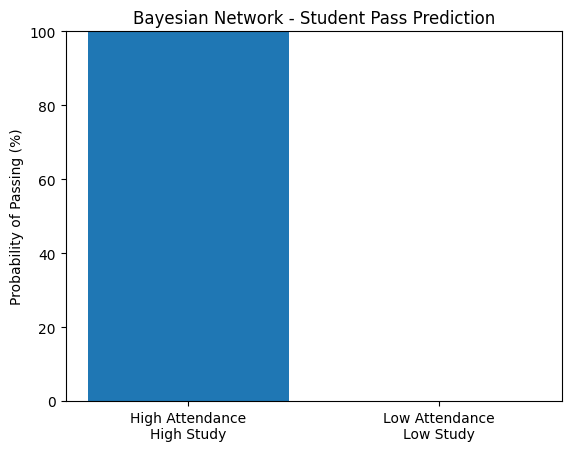

In [16]:
import matplotlib.pyplot as plt

conditions = [
    'High Attendance\nHigh Study',
    'Low Attendance\nLow Study'
]

probabilities = [
    pass_probability * 100,
    pass_probability2 * 100
]

plt.bar(conditions, probabilities)

plt.ylabel("Probability of Passing (%)")
plt.title("Bayesian Network - Student Pass Prediction")
plt.ylim(0, 100)

plt.show()